In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns 

In [3]:
dataframe = pd.read_csv("Zomato data .csv")
dataframe

,name,online_order,book_table,rate,votes,approx_cost(for two people),listed_in(type)
0,Jalsa,Yes,Yes,4.1/5,775,800,Buffet
1,Spice Elephant,Yes,No,4.1/5,787,800,Buffet
2,San Churro Cafe,Yes,No,3.8/5,918,800,Buffet
3,Addhuri Udupi Bhojana,No,No,3.7/5,88,300,Buffet
4,Grand Village,No,No,3.8/5,166,600,Buffet
...,...,...,...,...,...,...,...
143,Melting Melodies,No,No,3.3/5,0,100,Dining
144,New Indraprasta,No,No,3.3/5,0,150,Dining
145,Anna Kuteera,Yes,No,4.0/5,771,450,Dining
146,Darbar,No,No,3.0/5,98,800,Dining


In [4]:
dataframe.head()

,name,online_order,book_table,rate,votes,approx_cost(for two people),listed_in(type)
0,Jalsa,Yes,Yes,4.1/5,775,800,Buffet
1,Spice Elephant,Yes,No,4.1/5,787,800,Buffet
2,San Churro Cafe,Yes,No,3.8/5,918,800,Buffet
3,Addhuri Udupi Bhojana,No,No,3.7/5,88,300,Buffet
4,Grand Village,No,No,3.8/5,166,600,Buffet


In [5]:
dataframe.shape

(148, 7)

In [6]:
dataframe.info()

<class 'pandas.DataFrame'>
RangeIndex: 148 entries, 0 to 147
Data columns (total 7 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   name                         148 non-null    str  
 1   online_order                 148 non-null    str  
 2   book_table                   148 non-null    str  
 3   rate                         148 non-null    str  
 4   votes                        148 non-null    int64
 5   approx_cost(for two people)  148 non-null    int64
 6   listed_in(type)              148 non-null    str  
dtypes: int64(2), str(5)
memory usage: 12.7 KB


In [7]:
dataframe.isnull().sum()

name                           0
online_order                   0
book_table                     0
rate                           0
votes                          0
approx_cost(for two people)    0
listed_in(type)                0
dtype: int64

In [12]:
dataframe.duplicated().sum()

np.int64(0)

In [11]:
def handleRate(value):
    value = str(value).split('/')
    value = value[0]
    return float(value)

In [10]:

dataframe['rate'] = dataframe['rate'].apply(handleRate)

dataframe.head()


,name,online_order,book_table,rate,votes,approx_cost(for two people),listed_in(type)
0,Jalsa,Yes,Yes,4.1,775,800,Buffet
1,Spice Elephant,Yes,No,4.1,787,800,Buffet
2,San Churro Cafe,Yes,No,3.8,918,800,Buffet
3,Addhuri Udupi Bhojana,No,No,3.7,88,300,Buffet
4,Grand Village,No,No,3.8,166,600,Buffet


In [12]:
print(dataframe['rate'].head())
print(dataframe['rate'].dtype)

0    4.1
1    4.1
2    3.8
3    3.7
4    3.8
Name: rate, dtype: float64
float64


In [14]:
handleRate('4.1/5')

4.1

In [15]:
dataframe['rate'] = dataframe['rate'].apply(handleRate)
dataframe.head()

,name,online_order,book_table,rate,votes,approx_cost(for two people),listed_in(type)
0,Jalsa,Yes,Yes,4.1,775,800,Buffet
1,Spice Elephant,Yes,No,4.1,787,800,Buffet
2,San Churro Cafe,Yes,No,3.8,918,800,Buffet
3,Addhuri Udupi Bhojana,No,No,3.7,88,300,Buffet
4,Grand Village,No,No,3.8,166,600,Buffet


In [17]:
print("Rating data type:", dataframe['rate'].dtype)
print(dataframe['rate'].head())

Rating data type: float64
0    4.1
1    4.1
2    3.8
3    3.7
4    3.8
Name: rate, dtype: float64


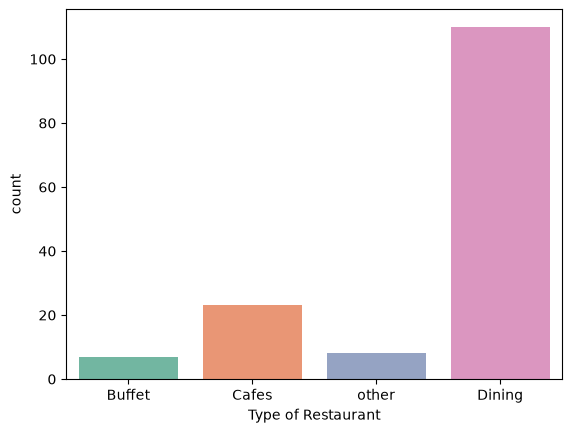

In [18]:
sns.countplot(
    x = dataframe['listed_in(type)'],
    hue = dataframe['listed_in(type)'],
    palette = 'Set2',
    legend = False
)

plt.xlabel("Type of Restaurant")
plt.show()

In [24]:
grouped_data = dataframe.groupby("listed_in(type)")["votes"].sum()

result = pd.DataFrame({"votes":grouped_data})

result

,votes
listed_in(type),
Buffet,3028
Cafes,6434
Dining,20363
other,9367


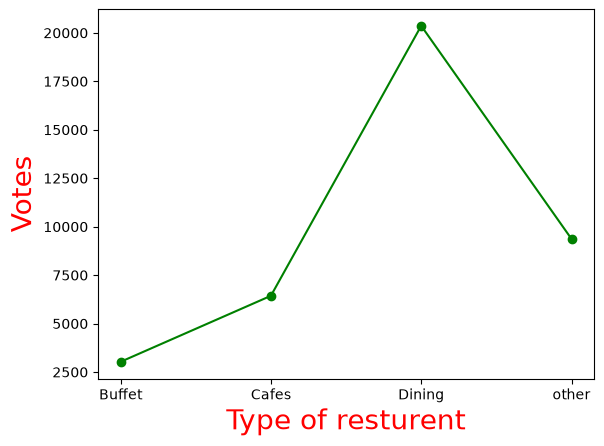

In [26]:
plt.plot(result, c="green",marker="o")

plt.xlabel("Type of resturent", c="red",size=20)
plt.ylabel("Votes",c="red",size=20)

plt.show()           

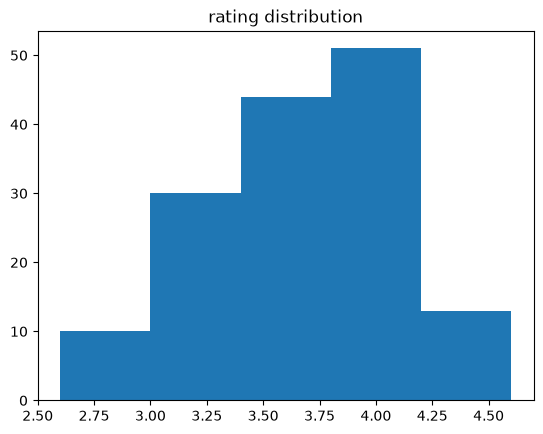

In [27]:
plt.hist(dataframe['rate'],bins = 5)

plt.title("rating distribution")

plt.show()

In [28]:
dataframe['approx_cost(for two people)'].value_counts()

approx_cost(for two people)
300    23
200    16
150    16
400    15
500    14
600    13
800    12
450     6
100     6
250     6
700     5
550     3
750     3
350     3
650     2
900     2
850     2
950     1
Name: count, dtype: int64

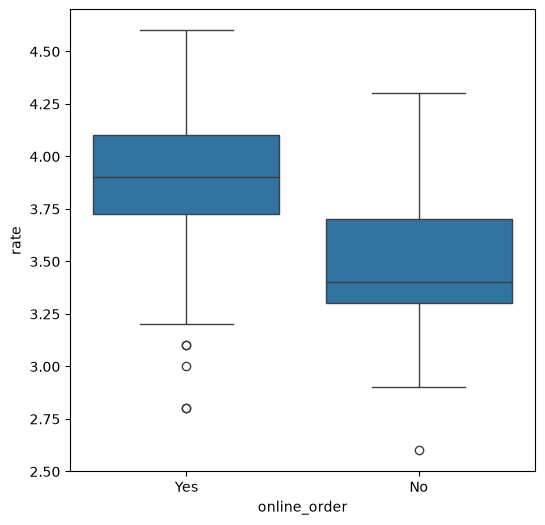

In [29]:
plt.figure(figsize=(6,6))

sns.boxplot(x='online_order',y='rate',data = dataframe)

plt.show()

In [30]:
pivot_table = dataframe.pivot_table(
    index = 'listed_in(type)',
    columns = 'online_order',
    aggfunc = 'size',
    fill_value = 0
)

pivot_table

online_order,No,Yes
listed_in(type),,
Buffet,3,4
Cafes,8,15
Dining,77,33
other,2,6


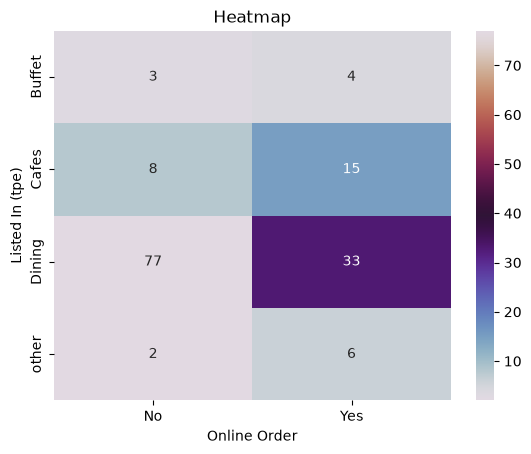

In [33]:
sns.heatmap(pivot_table,annot=True, cmap="twilight", fmt='d')

plt.title("Heatmap")
plt.xlabel("Online Order")
plt.ylabel("Listed In (tpe)")
plt.show()

In [34]:
offline_orders = dataframe[dataframe['online_order'] =='No']

offline_orders.head()

,name,online_order,book_table,rate,votes,approx_cost(for two people),listed_in(type)
3,Addhuri Udupi Bhojana,No,No,3.7,88,300,Buffet
4,Grand Village,No,No,3.8,166,600,Buffet
6,Rosewood International Hotel - Bar & Restaurant,No,No,3.6,8,800,Buffet
13,Caf-Eleven,No,No,4.0,424,450,Cafes
18,T3H Cafe,No,No,3.9,93,300,Cafes


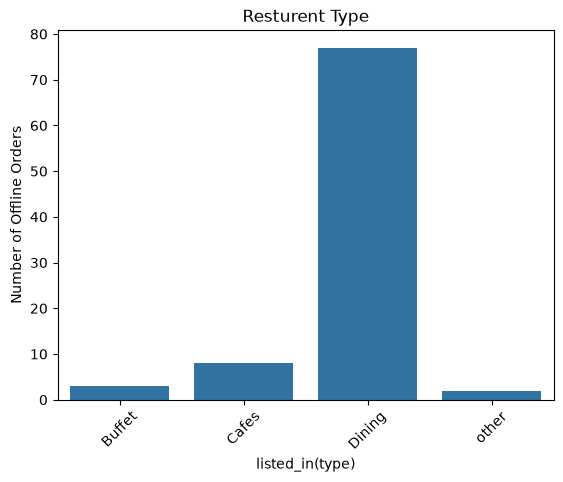

In [36]:
sns.countplot(data = offline_orders, x='listed_in(type)')

plt.title("Restuarent Types with Offline Orders")
plt.title("Resturent Type")
plt.ylabel("Number of Offline Orders")
plt.xticks(rotation = 45)

plt.show()
